In [ ]:
# Persiapan tambahan untuk notebook.
import sys
import time
import hashlib
import urllib.request
from pathlib import Path
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False})
try:
    from threadpoolctl import threadpool_limits
    blas_limiter = threadpool_limits(limits=1)
    print('BLAS dibatasi ke satu thread untuk eksperimen NumPy ini.')
except ImportError:
    print('threadpoolctl tidak tersedia; memakai pengaturan BLAS lingkungan.')
print('Python:', sys.version.split()[0])
print('NumPy:', np.__version__)
print('Matplotlib:', matplotlib.__version__)

BLAS dibatasi ke satu thread untuk eksperimen NumPy ini.
Python: 3.13.16
NumPy: 2.1.3
Matplotlib: 3.10.0


## 2. Ringkasan Chapter 8

Jaringan yang sangat cocok dengan data training belum tentu berhasil pada data baru. Buku memperlihatkan model MNIST yang akhirnya mencapai training accuracy 100%, sementara test accuracy turun setelah peningkatan pada epoch awal. Contoh ini memperkenalkan overfitting: model mempelajari rincian atau pola kebetulan yang tidak membantu generalisasi.

Early stopping membatasi proses tersebut dengan memilih checkpoint berdasarkan validation set. Test set digunakan untuk penilaian hasil, bukan untuk menentukan kapan berhenti atau mengatur parameter. Regularisasi secara lebih luas berusaha mendorong model mempelajari hubungan yang berguna di luar sampel training.

Dropout secara acak mematikan hidden activation selama training. Unit yang dipertahankan dikalikan faktor kebalikan keep probability agar nilai harapannya tidak berubah. Pada inference, seluruh unit digunakan tanpa mask. Intuisi subnetwork dan ensemble membantu menjelaskan mengapa model tidak terlalu bergantung pada kombinasi unit tertentu.

Mini-batch memproses beberapa sampel sekaligus serta memakai rata-rata kontribusi gradien. Perkalian matriks dapat mengurangi overhead komputasi. Namun, keuntungan kecepatan, kestabilan, dan generalisasi tetap dipengaruhi implementasi serta pasangan batch size-learning rate. Notebook menguji listing buku dan membandingkannya dengan implementasi yang melakukan satu update per batch sesuai rumus.

**Rujukan:** Trask (2019), hlm. 145-160.

## 3. Peta subbab dan cakupan

| Subbab buku | Halaman cetak | Pengerjaan |
| --- | --- | --- |
| Three-layer network on MNIST | 146-147 | Persiapan data dan reproduksi 350 epoch, hidden size 40 |
| Well, that was easy | 148 | Reproduksi evaluasi pada 10.000 gambar test |
| Memorization vs. generalization | 149 | Kurva training, validation, dan test |
| Overfitting in neural networks | 150 | Definisi, gap performa, dan analogi cetakan garpu |
| Where overfitting comes from | 151 | Signal, noise, dan rincian data |
| The simplest regularization: Early stopping | 152 | Monitor validation, patience, dan checkpoint tambahan |
| Industry standard regularization: Dropout | 153 | Mask Bernoulli serta kapasitas model |
| Why dropout works: Ensembling works | 154 | Subnetwork, shared weights, dan batas intuisi averaging |
| Dropout in code | 155-156 | Mask/scaling dan reproduksi 300 epoch, hidden size 100 |
| Dropout evaluated on MNIST | 157 | Perbandingan checkpoint dan mode evaluasi |
| Batch gradient descent | 158-160 | Reproduksi batch size 100, pemeriksaan update, dan mini-batch konsisten |
| Summary | 160 | Hubungan regularisasi, optimisasi, dan generalisasi |

Evaluasi vectorized, validation tambahan, grafik, pemeriksaan gradien, serta trainer mini-batch konsisten merupakan pendalaman. Potongan kode yang berulang dijelaskan melalui program lengkapnya.

## 4. MNIST: input, label, dan normalisasi

MNIST berisi gambar grayscale digit 0-9 berukuran 28 × 28. File resmi menyediakan 60.000 gambar training dan 10.000 gambar test. Eksperimen buku hanya memakai **1.000 gambar training pertama**, sehingga hasilnya menggambarkan kondisi data training terbatas.

Gambar diratakan menjadi 784 feature. Pembagian nilai pixel dengan 255 membawa rentang input dari 0-255 ke 0-1. Transformasi ini mempertahankan urutan pixel dan dilakukan dengan cara yang sama pada training, validation, dan test.

Label integer diubah menjadi one-hot vector berukuran 10. Misalnya, digit 3 memiliki target dengan nilai 1 pada indeks 3 dan 0 pada indeks lainnya. Output model berupa sepuluh skor linear; kelas prediksi adalah indeks skor terbesar dengan `argmax`.

**Adaptasi loader:** buku menggunakan `from keras.datasets import mnist` dan `mnist.load_data()`. Sel berikut menyediakan antarmuka `load_data()` tambahan yang membaca file resmi yang sama langsung dengan NumPy. Pembacaan menggunakan `allow_pickle=False` dan hash file diperiksa untuk memastikan cache sesuai.

**Rujukan:** Trask (2019), hlm. 147; [dokumentasi resmi MNIST Keras](https://keras.io/api/datasets/mnist/).

In [ ]:
# Adaptasi loader: file MNIST resmi yang digunakan Keras.
MNIST_URL = 'https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz'
MNIST_SHA256 = '731c5ac602752760c8e48fbffcf8c3b850d9dc2a2aedcf2cc48468fc17b673d1'
DATA_CACHE = Path('data/mnist.npz')

class NumpyMNISTLoader:
    @staticmethod
    def load_data():
        DATA_CACHE.parent.mkdir(parents=True, exist_ok=True)
        if not DATA_CACHE.exists():
            urllib.request.urlretrieve(MNIST_URL, DATA_CACHE)
        actual_hash = hashlib.sha256(DATA_CACHE.read_bytes()).hexdigest()
        if actual_hash != MNIST_SHA256:
            raise ValueError('Hash cache MNIST berbeda. Hapus cache lalu unduh ulang.')
        with np.load(DATA_CACHE, allow_pickle=False) as dataset:
            return ((dataset['x_train'], dataset['y_train']),
                    (dataset['x_test'], dataset['y_test']))

mnist = NumpyMNISTLoader()
(x_train, y_train), (x_test, y_test) = mnist.load_data()
print('Data training:', x_train.shape, y_train.shape)
print('Data test:', x_test.shape, y_test.shape)
print('Hash MNIST sesuai file yang digunakan saat penyusunan.')

Data training: (60000, 28, 28) (60000,)
Data test: (10000, 28, 28) (10000,)
Hash MNIST sesuai file yang digunakan saat penyusunan.


In [ ]:
# Reproduksi preprocessing halaman 147.
images, labels = (x_train[0:1000].reshape(1000, 28*28) / 255,
                  y_train[0:1000])
one_hot_labels = np.zeros((len(labels), 10))
for i, l in enumerate(labels):
    one_hot_labels[i][l] = 1
labels = one_hot_labels

test_images = x_test.reshape(len(x_test), 28*28) / 255
test_labels = np.zeros((len(y_test), 10))
for i, l in enumerate(y_test):
    test_labels[i][l] = 1

# Tambahan validation: indeks training 1000-1999, tidak masuk training model.
validation_images = x_train[1000:2000].reshape(1000, 28*28) / 255
validation_labels = np.eye(10)[y_train[1000:2000]]
training_indices = np.arange(0, 1000)
validation_indices = np.arange(1000, 2000)
assert np.intersect1d(training_indices, validation_indices).size == 0
assert images.shape == (1000, 784) and labels.shape == (1000, 10)
assert test_images.shape == (10000, 784) and test_labels.shape == (10000, 10)
np.testing.assert_allclose(labels.sum(axis=1), 1)
print('Training:', images.shape, labels.shape)
print('Validation:', validation_images.shape, validation_labels.shape)
print('Test:', test_images.shape, test_labels.shape)
print('Rentang pixel training:', images.min(), images.max())

Training: (1000, 784) (1000, 10)
Validation: (1000, 784) (1000, 10)
Test: (10000, 784) (10000, 10)
Rentang pixel training: 0.0 1.0


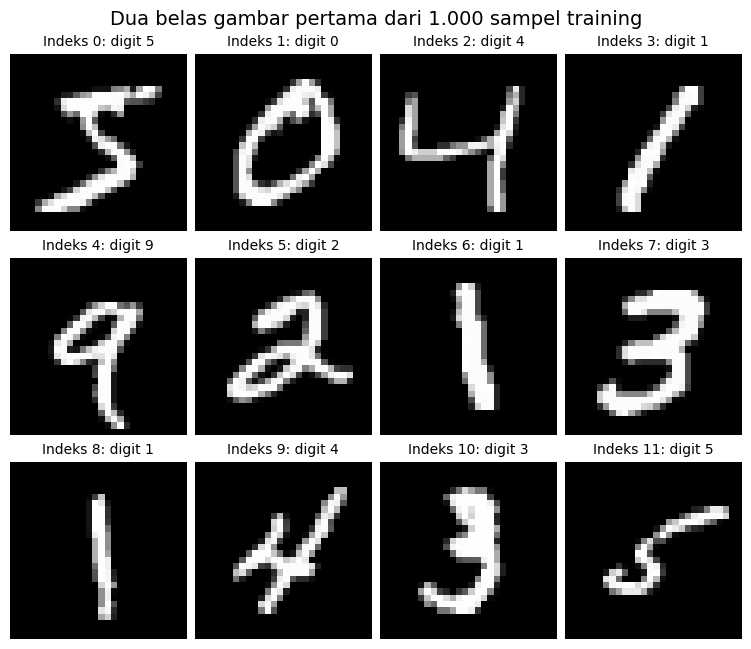

In [ ]:
# Visualisasi tambahan: gambar MNIST yang benar-benar dipakai.
fig, axes = plt.subplots(3, 4, figsize=(7.4, 6.4), layout='constrained')
for index, ax in enumerate(axes.ravel()):
    ax.imshow(x_train[index], cmap='gray', vmin=0, vmax=255)
    ax.set_title(f'Indeks {index}: digit {int(y_train[index])}', fontsize=10)
    ax.axis('off')
fig.suptitle('Dua belas gambar pertama dari 1.000 sampel training', fontsize=14)
plt.show()

## 5. Arsitektur, error, dan accuracy

Untuk hidden width $H$, bentuk jaringan adalah:

$$
X_{N\times784}\;\longrightarrow\;W_{0,784\times H}
\;\longrightarrow\;h=\operatorname{ReLU}(XW_0)
\;\longrightarrow\;W_{1,H\times10}\;\longrightarrow\;\hat Y_{N\times10}.
$$

Tidak ada variabel bias terpisah. Baseline memakai $H=40$, sedangkan dropout dan batch memakai $H=100$. Karena ukuran model berubah, perbandingan buku tidak mengisolasi efek dropout saja.

Buku mencetak `sum((Y - prediction)**2) / N`. Besaran ini adalah **rata-rata SSE per gambar**, bukan MSE per elemen output; MSE atas seluruh elemen adalah nilai tersebut dibagi 10. Accuracy hanya memeriksa apakah `argmax` prediksi sama dengan `argmax` target.

Loss untuk menjelaskan gradien dapat ditulis $L=\tfrac12\|\hat y-y\|^2$ per sampel. Delta sumber memakai `target - prediction`, sehingga update menggunakan tanda **plus**. Faktor setengah menjelaskan mengapa delta tidak memiliki faktor 2 walaupun log menampilkan SSE penuh.

**Catatan turunan ReLU:** listing menggunakan `relu2deriv(output) = output >= 0` pada activation setelah ReLU. Karena activation ini selalu nonnegatif, mask menjadi 1 bahkan untuk nilai preactivation negatif yang dipotong menjadi nol. Ini berbeda dari turunan ReLU yang benar pada preactivation negatif. Perilaku tersebut dipertahankan untuk reproduksi dan diperbaiki pada pendalaman.

**Rujukan:** Trask (2019), hlm. 147 dan 156.

In [ ]:
# Reproduksi definisi activation dan mask sumber; demonstrasi tambahan.
relu = lambda x: (x >= 0) * x
relu2deriv = lambda output: output >= 0
z_demo = np.array([[-1.0, 0.0, 1.0]])
h_demo = relu(z_demo)
print('Preactivation:', z_demo)
print('Activation:', h_demo)
print('Mask listing pada activation:', relu2deriv(h_demo).astype(int))
print('Mask konsisten memakai z > 0:', (z_demo > 0).astype(int))
print('Pada z = 0, pendalaman memilih subgradien 0.')

Preactivation: [[-1.  0.  1.]]
Activation: [[-0.  0.  1.]]
Mask listing pada activation: [[1 1 1]]
Mask konsisten memakai z > 0: [[0 0 1]]
Pada z = 0, pendalaman memilih subgradien 0.


## 6. Evaluasi tetap dan pemantauan validation

Log training sumber dijumlahkan sebelum update tiap sampel atau batch. Bobot berubah di sepanjang epoch; pada dropout, mask juga berubah. Nilainya berbeda dari evaluasi seluruh dataset dengan satu bobot akhir yang tetap dan dropout dimatikan.

Fungsi tambahan berikut melakukan evaluasi tersebut secara vectorized. Prediksi tetap sama dengan forward per gambar; tidak ada mask, update, atau pemanggilan random. Evaluasi loop buku direproduksi terpisah setelah baseline untuk memeriksa kesesuaiannya.

Validation tambahan dipakai untuk simulasi kebijakan early stopping. Monitor menyimpan checkpoint ketika validation SSE per gambar membaik setidaknya `min_delta`, dan mencatat sinyal berhenti setelah `patience` epoch tanpa perbaikan. **Reproduksi tetap menjalankan seluruh 350 epoch**; monitor tidak menghentikan loop sumber. Setelah sinyal berhenti, checkpoint monitor dibekukan dan dapat dievaluasi secara terpisah.

Test accuracy dicatat untuk mereproduksi kurva buku, tetapi tidak dipakai oleh monitor atau untuk memilih parameter. **Rujukan:** Trask (2019), hlm. 148-149 dan 152.

In [ ]:
# Tambahan: evaluasi dalam mode inference dan monitor checkpoint.
def evaluate_fixed(inputs, targets, w0, w1):
    predictions = relu(inputs @ w0) @ w1
    mean_sse = float(np.sum((targets - predictions) ** 2) / len(inputs))
    accuracy = float(np.mean(np.argmax(predictions, axis=1) ==
                             np.argmax(targets, axis=1)))
    return {'mean_sse': mean_sse, 'accuracy': accuracy}

def observe_validation(state, validation_sse, epoch_index, w0, w1):
    if state['stop_index'] is not None:
        return
    if validation_sse < state['best_sse'] - state['min_delta']:
        state['best_sse'] = validation_sse
        state['best_index'] = epoch_index
        state['weights'] = (w0.copy(), w1.copy())
        state['wait'] = 0
    else:
        state['wait'] += 1
        if state['wait'] >= state['patience']:
            state['stop_index'] = epoch_index

early_state = {'best_sse': float('inf'), 'best_index': None,
               'stop_index': None, 'weights': None, 'wait': 0,
               'min_delta': 1e-4, 'patience': 10}
print('Monitor hanya memakai validation SSE per gambar.')
print('min_delta =', early_state['min_delta'], '; patience =', early_state['patience'])

Monitor hanya memakai validation SSE per gambar.
min_delta = 0.0001 ; patience = 10


## 7. Reproduksi jaringan tiga lapisan tanpa dropout

Konfigurasi halaman 147 adalah seed `1`, learning rate `0.005`, hidden size `40`, dan `350` epoch. Seluruh 1.000 sampel diproses berurutan tanpa shuffle. Definisi ReLU dan `relu2deriv` mengikuti sumber.

Loop training dipertahankan. History, timer, evaluasi vectorized, dan monitor validation merupakan tambahan untuk analisis. Evaluasi tersebut tidak mengubah bobot maupun urutan bilangan random. Indeks buku `I:0` berarti satu epoch sudah selesai; grafik menggunakan `epoch = j + 1`.

**Rujukan:** Trask (2019), hlm. 147-149.

In [ ]:
# Reproduksi inti baseline, ditambah pencatatan hasil.
np.random.seed(1)
relu = lambda x: (x >= 0) * x
relu2deriv = lambda x: x >= 0
alpha, iterations, hidden_size, pixels_per_image, num_labels = (0.005, 350, 40, 784, 10)
weights_0_1 = 0.2*np.random.random((pixels_per_image, hidden_size)) - 0.1
weights_1_2 = 0.2*np.random.random((hidden_size, num_labels)) - 0.1
baseline_history = []
baseline_validation_history = []
baseline_seconds = 0.0
baseline_updates = 0

for j in range(iterations):
    step_started = time.perf_counter()
    error, correct_cnt = (0.0, 0)
    for i in range(len(images)):
        layer_0 = images[i:i+1]
        layer_1 = relu(np.dot(layer_0, weights_0_1))
        layer_2 = np.dot(layer_1, weights_1_2)
        error += np.sum((labels[i:i+1] - layer_2) ** 2)
        correct_cnt += int(np.argmax(layer_2) == np.argmax(labels[i:i+1]))
        layer_2_delta = labels[i:i+1] - layer_2
        layer_1_delta = layer_2_delta.dot(weights_1_2.T) * relu2deriv(layer_1)
        weights_1_2 += alpha * layer_1.T.dot(layer_2_delta)
        weights_0_1 += alpha * layer_0.T.dot(layer_1_delta)
        baseline_updates += 1
    baseline_seconds += time.perf_counter() - step_started

    # Tambahan evaluasi tetap; tidak memengaruhi update sumber.
    validation_metrics = evaluate_fixed(validation_images, validation_labels,
                                        weights_0_1, weights_1_2)
    baseline_validation_history.append({'epoch': j+1, **validation_metrics})
    observe_validation(early_state, validation_metrics['mean_sse'], j,
                       weights_0_1, weights_1_2)
    if j % 10 == 0 or j == iterations-1:
        train_fixed = evaluate_fixed(images, labels, weights_0_1, weights_1_2)
        test_fixed = evaluate_fixed(test_images, test_labels, weights_0_1, weights_1_2)
        row = {'index': j, 'epoch': j+1, 'online_sse': float(error/len(images)),
               'online_accuracy': correct_cnt/len(images),
               'train': train_fixed, 'validation': validation_metrics, 'test': test_fixed}
        baseline_history.append(row)
        print(f"I:{j} Train-Err:{row['online_sse']:.6f} Train-Acc:{row['online_accuracy']:.4f} "
              f"Test-Err:{test_fixed['mean_sse']:.6f} Test-Acc:{test_fixed['accuracy']:.4f}")

baseline_weights = (weights_0_1.copy(), weights_1_2.copy())
print('Jumlah update baseline:', baseline_updates)

I:0 Train-Err:0.722024 Train-Acc:0.5370 Test-Err:0.601963 Test-Acc:0.6488
I:10 Train-Err:0.312005 Train-Acc:0.9010 Test-Err:0.420290 Test-Acc:0.8114
I:20 Train-Err:0.260943 Train-Acc:0.9300 Test-Err:0.414371 Test-Acc:0.8111
I:30 Train-Err:0.232863 Train-Acc:0.9460 Test-Err:0.417447 Test-Acc:0.8066
I:40 Train-Err:0.215986 Train-Acc:0.9560 Test-Err:0.426847 Test-Acc:0.8019
I:50 Train-Err:0.204135 Train-Acc:0.9660 Test-Err:0.437597 Test-Acc:0.7982
I:60 Train-Err:0.194818 Train-Acc:0.9670 Test-Err:0.448181 Test-Acc:0.7921
I:70 Train-Err:0.186759 Train-Acc:0.9750 Test-Err:0.458125 Test-Acc:0.7864
I:80 Train-Err:0.179604 Train-Acc:0.9790 Test-Err:0.466697 Test-Acc:0.7817
I:90 Train-Err:0.172835 Train-Acc:0.9810 Test-Err:0.474430 Test-Acc:0.7758
I:100 Train-Err:0.166718 Train-Acc:0.9840 Test-Err:0.482190 Test-Acc:0.7706
I:110 Train-Err:0.161888 Train-Acc:0.9840 Test-Err:0.489703 Test-Acc:0.7686
I:120 Train-Err:0.157628 Train-Acc:0.9860 Test-Err:0.496224 Test-Acc:0.7660
I:130 Train-Err:0.15344

## 8. Reproduksi evaluasi pada test set

Sel berikut memproses semua 10.000 gambar test satu per satu, mengikuti halaman 148. Evaluasi menggunakan bobot akhir baseline, tanpa melakukan update. Hasil dibandingkan dengan fungsi vectorized tambahan.

Test set memiliki sampel berbeda dari training model. Perbedaan performa menunjukkan bahwa fit training dan generalisasi perlu diperiksa secara terpisah. Angka buku pada indeks 349 adalah test accuracy `0.7073`.

**Rujukan:** Trask (2019), hlm. 148-149.

In [ ]:
# Reproduksi loop evaluasi halaman 148.
if j % 10 == 0 or j == iterations-1:
    error, correct_cnt = (0.0, 0)
    for i in range(len(test_images)):
        layer_0 = test_images[i:i+1]
        layer_1 = relu(np.dot(layer_0, weights_0_1))
        layer_2 = np.dot(layer_1, weights_1_2)
        error += np.sum((test_labels[i:i+1] - layer_2) ** 2)
        correct_cnt += int(np.argmax(layer_2) == np.argmax(test_labels[i:i+1]))
    baseline_test_loop = {'mean_sse': float(error/len(test_images)),
                          'accuracy': correct_cnt/len(test_images)}
    print('Test-Err:', baseline_test_loop['mean_sse'])
    print('Test-Acc:', baseline_test_loop['accuracy'])

# Verifikasi tambahan kesetaraan dua cara evaluasi.
np.testing.assert_allclose(baseline_test_loop['mean_sse'],
                           baseline_history[-1]['test']['mean_sse'], rtol=1e-12)
assert baseline_test_loop['accuracy'] == baseline_history[-1]['test']['accuracy']

Test-Err: 0.6534055358949843
Test-Acc: 0.7073


## 9. Memorization vs. generalization dan overfitting

Model dapat memanfaatkan pola khusus pada 1.000 gambar training yang tidak membantu saat menghadapi variasi lain. Analogi cetakan garpu pada buku menggambarkan hal ini: cetakan yang terlalu mengikuti garpu tiga cabang bisa menolak garpu empat cabang, walaupun keduanya masuk kategori yang sama.

Pada data gambar, rincian latar, ketebalan garis, posisi, atau gangguan pixel dapat menjadi pola kebetulan. Namun, rincian tidak selalu noise; relevansinya bergantung pada tugas dan distribusi data. Model juga tidak selalu mempelajari bentuk umum lebih dahulu lalu noise belakangan secara mutlak. Kurva performa memberikan bukti empiris yang lebih berguna daripada menganggap analogi berlaku untuk semua jaringan.

Dalam contoh buku, training accuracy terus naik, sementara test accuracy mulai menurun setelah peningkatan awal. Kondisi ini konsisten dengan overfitting. Pada masalah lain, penurunan test dapat juga berkaitan dengan perbedaan distribusi atau kualitas data, sehingga gap saja belum menjelaskan seluruh penyebab.

**Accuracy 100% tidak sama dengan loss nol.** Semua kelas hasil `argmax` dapat benar ketika skor masih berbeda dari one-hot target. Karena itu, model bisa terus memperoleh gradien walaupun seluruh gambar training sudah terklasifikasi benar. Angka SSE training yang masih positif pada buku memperlihatkan perbedaan ini.

**Rujukan:** Trask (2019), hlm. 149-151 dan 154.

In [ ]:
# Tambahan: memeriksa beberapa checkpoint sumber.
baseline_first = baseline_history[0]
baseline_last = baseline_history[-1]
baseline_peak_logged = max(baseline_history, key=lambda row: row['test']['accuracy'])
print('Training online akhir:', baseline_last['online_accuracy'])
print('SSE/gambar training online akhir:', baseline_last['online_sse'])
print('Test accuracy akhir:', baseline_last['test']['accuracy'])
print('Puncak test pada checkpoint yang dicatat:', baseline_peak_logged['test']['accuracy'],
      'di indeks', baseline_peak_logged['index'])
print('Puncak test di atas hanya deskriptif; tidak dipakai memilih checkpoint.')
np.testing.assert_allclose(baseline_first['online_sse'], 0.7220241827755525, rtol=1e-10)
assert baseline_first['online_accuracy'] == 0.537
assert baseline_last['online_accuracy'] == 1.0
assert baseline_last['test']['accuracy'] == 0.7073
assert baseline_updates == 350000

Training online akhir: 1.0
SSE/gambar training online akhir: 0.10881979854066498
Test accuracy akhir: 0.7073
Puncak test pada checkpoint yang dicatat: 0.8114 di indeks 10
Puncak test di atas hanya deskriptif; tidak dipakai memilih checkpoint.


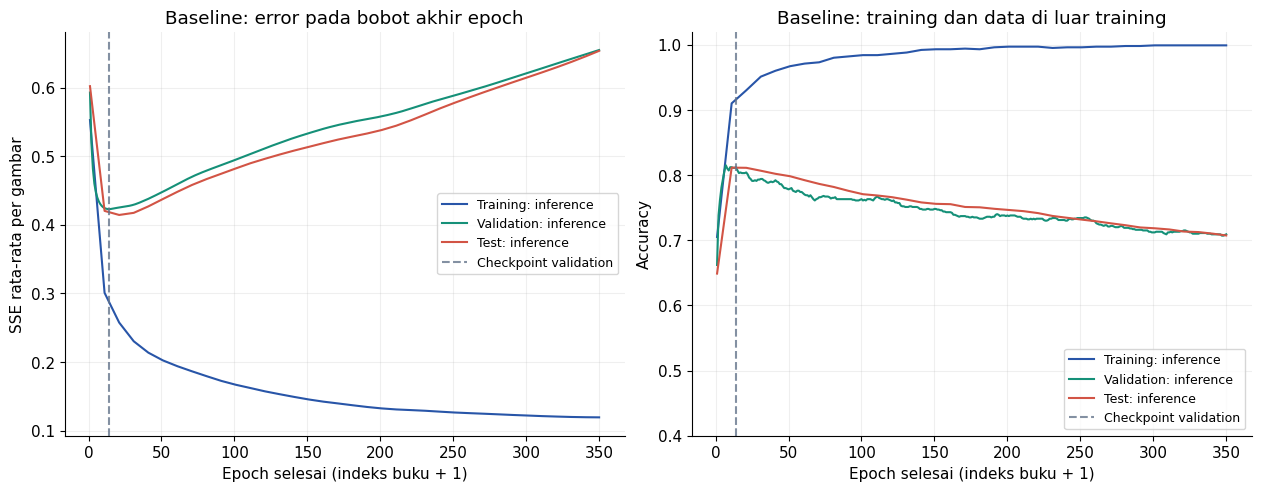

In [ ]:
# Visualisasi tambahan: semua garis memakai bobot tetap dalam mode inference.
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8), layout='constrained')
epochs = [row['epoch'] for row in baseline_history]
validation_epochs = [row['epoch'] for row in baseline_validation_history]
for ax, key, ylabel in [(axes[0], 'mean_sse', 'SSE rata-rata per gambar'),
                        (axes[1], 'accuracy', 'Accuracy')]:
    ax.plot(epochs, [row['train'][key] for row in baseline_history],
            color='#2855a8', label='Training: inference')
    ax.plot(validation_epochs, [row[key] for row in baseline_validation_history],
            color='#159078', label='Validation: inference')
    ax.plot(epochs, [row['test'][key] for row in baseline_history],
            color='#d25445', label='Test: inference')
    if early_state['best_index'] is not None:
        ax.axvline(early_state['best_index'] + 1, color='#64748b',
                   linestyle='--', alpha=0.8, label='Checkpoint validation')
    ax.set_xlabel('Epoch selesai (indeks buku + 1)')
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.2)
    ax.legend(fontsize=9)
axes[0].set_title('Baseline: error pada bobot akhir epoch')
axes[1].set_title('Baseline: training dan data di luar training')
axes[1].set_ylim(0.4, 1.02)
plt.show()

## 10. Early stopping dan pembagian data

Early stopping memilih checkpoint berdasarkan performa validation yang tidak dipakai untuk menyesuaikan bobot. `Patience` memberi toleransi terhadap fluktuasi; `min_delta` menentukan perbaikan minimum yang dianggap berarti. Ketika sinyal berhenti muncul, bobot terbaik yang disimpan dipulihkan untuk evaluasi.

| Dataset | Peran pada notebook | Digunakan untuk update? |
| --- | --- | --- |
| Training: 1.000 gambar pertama | Menghitung update sumber dan tambahan | Ya |
| Validation: 1.000 gambar berikutnya | Memantau checkpoint early stopping | Tidak |
| Test: 10.000 gambar resmi | Penilaian dan reproduksi kurva buku | Tidak |

Monitor menggunakan **validation SSE per gambar**, bukan test accuracy. Memilih epoch dari puncak test, lalu melaporkan test yang sama sebagai penilaian independen, dapat membuat estimasi optimistis. Validation juga dapat mengalami overfitting jika terlalu sering digunakan untuk mencoba banyak keputusan.

Dalam notebook, simulasi monitor dijalankan bersama baseline lengkap. Ini menjaga reproduksi 350 epoch sekaligus menunjukkan bobot mana yang akan dipilih oleh kebijakan berhenti yang ditetapkan sebelumnya. Waktu sinyal berhenti dan epoch checkpoint berbeda: model dapat menunggu beberapa epoch setelah perbaikan terakhir.

**Rujukan:** Trask (2019), hlm. 152.

In [ ]:
# Tambahan: evaluasi checkpoint yang dipilih hanya oleh validation.
early_weights = early_state['weights']
assert early_weights is not None
early_train = evaluate_fixed(images, labels, *early_weights)
early_validation = evaluate_fixed(validation_images, validation_labels, *early_weights)
early_test = evaluate_fixed(test_images, test_labels, *early_weights)
print('Epoch checkpoint validation:', early_state['best_index'] + 1)
print('Epoch sinyal berhenti:', None if early_state['stop_index'] is None
      else early_state['stop_index'] + 1)
print('Validation SSE/gambar checkpoint:', early_validation['mean_sse'])
print('Test accuracy baseline 350 epoch:', baseline_last['test']['accuracy'])
print('Test accuracy checkpoint validation:', early_test['accuracy'])
print('Loop reproduksi tetap menyelesaikan 350 epoch; bobot checkpoint disimpan terpisah.')

Epoch checkpoint validation: 14
Epoch sinyal berhenti: 24
Validation SSE/gambar checkpoint: 0.42290409743325735
Test accuracy baseline 350 epoch: 0.7073
Test accuracy checkpoint validation: 0.8121
Loop reproduksi tetap menyelesaikan 350 epoch; bobot checkpoint disimpan terpisah.


## 11. Regularisasi dan kapasitas model

Regularisasi mencakup cara mendorong generalisasi, misalnya membatasi parameter, menambah penalti, melakukan perturbasi saat training, atau memilih checkpoint sebelum training terlalu lama. Chapter 8 menitikberatkan early stopping dan dropout.

Kapasitas model menunjukkan keragaman fungsi yang dapat direpresentasikan. Model lebih besar dapat menangkap hubungan yang rumit, tetapi juga dapat mencocokkan pola yang tidak stabil jika data terbatas. Model kecil tetap dapat overfit pada kondisi tertentu; sebaliknya, ukuran besar tidak otomatis menghasilkan generalisasi yang buruk. Kualitas data, metode training, dan regularisasi ikut menentukan hasil.

Analogi tanah liat atau batu pada buku membantu membayangkan batas kemampuan representasi. Akan tetapi, regularisasi tidak sekadar menghapus semua detail gambar. Tujuannya adalah mempertahankan informasi yang berguna untuk target dan mengurangi ketergantungan pada pola yang tidak bertahan pada data lain.

**Rujukan:** Trask (2019), hlm. 151-153.

## 12. Dropout: mask Bernoulli dan inverted scaling

Misalkan hidden activation sebelum dropout adalah $h$. Pada training, setiap unit memiliki mask $m_j\sim\operatorname{Bernoulli}(q)$, dengan $q$ sebagai **keep probability**. Buku menggunakan $q=0.5$, sehingga peluang mematikan unit adalah $1-q=0.5$.

$$
\tilde h=h\odot\frac{m}{q},\qquad
\mathbb E[\tilde h_j\mid h_j]=h_j\frac{\mathbb E[m_j]}q=h_j.
$$

Faktor `2` pada listing adalah $1/0.5$. Untuk satu mask, jumlah unit aktif tidak harus tepat setengah. Pernyataan 50% berlaku sebagai peluang per unit, bukan kuota persis pada setiap sampel.

| Mode | Hidden activation | Pemakaian random mask |
| --- | --- | --- |
| Training | $h\odot m/q$ | Ya |
| Inference/validation/test | $h$ | Tidak |

Dengan inverted dropout, inference tidak mengalikan activation dengan `2` atau keep probability lagi. Nilai harapan dipertahankan, tetapi realisasi activation dan skor training tetap berfluktuasi.

**Rujukan:** Trask (2019), hlm. 153 dan 155.

In [ ]:
# Tambahan: contoh mask dan pemeriksaan nilai harapan dropout.
keep_probability = 0.5
hidden_example = np.array([[0.0, 0.25, 0.5, 0.75, 1.0, 1.25, 1.5, 1.75]])
mask_rng = np.random.RandomState(7)
mask_example = mask_rng.randint(2, size=hidden_example.shape)
training_hidden_example = hidden_example * mask_example / keep_probability
inference_hidden_example = hidden_example.copy()
many_masks = mask_rng.randint(2, size=(20000, hidden_example.shape[1]))
monte_carlo_mean = (many_masks * hidden_example / keep_probability).mean(axis=0)
print('Activation awal:', hidden_example)
print('Satu mask:', mask_example)
print('Jumlah unit dipertahankan:', int(mask_example.sum()), 'dari', mask_example.size)
print('Activation saat training:', training_hidden_example)
print('Rata-rata 20.000 mask:', monte_carlo_mean)
print('Target nilai harapan:', hidden_example[0])
assert np.max(np.abs(monte_carlo_mean - hidden_example[0])) < 0.05
np.testing.assert_allclose(inference_hidden_example, hidden_example)

Activation awal: [[0.   0.25 0.5  0.75 1.   1.25 1.5  1.75]]
Satu mask: [[1 0 1 0 1 1 1 1]]
Jumlah unit dipertahankan: 6 dari 8
Activation saat training: [[0.  0.  1.  0.  2.  2.5 3.  3.5]]
Rata-rata 20.000 mask: [0.       0.24595  0.49175  0.75165  0.9999   1.240625 1.49085  1.7619  ]
Target nilai harapan: [0.   0.25 0.5  0.75 1.   1.25 1.5  1.75]


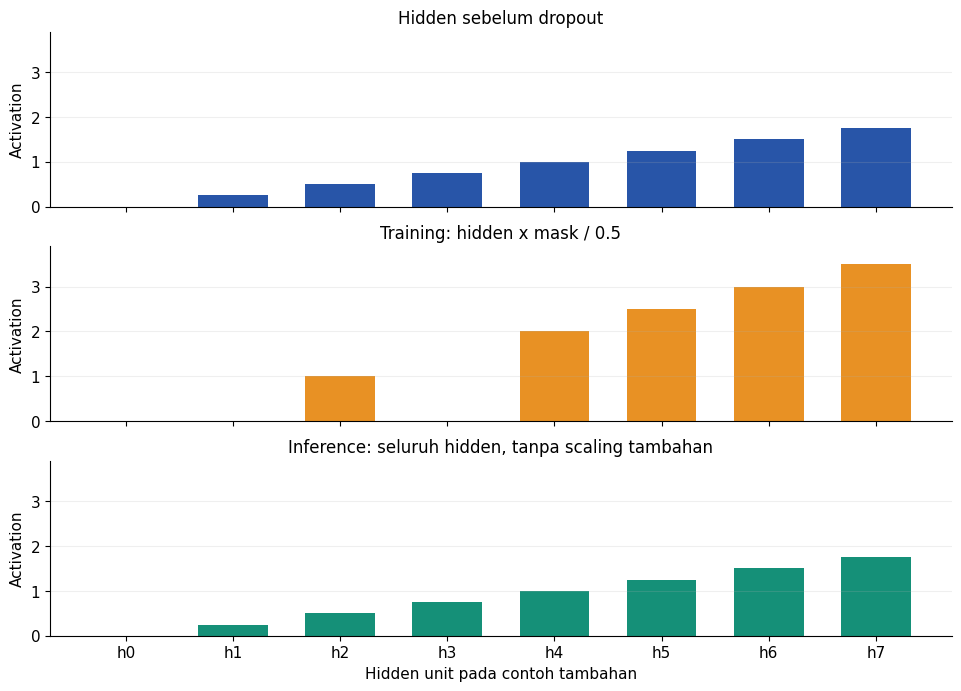

In [ ]:
# Visualisasi tambahan: satu mask tidak harus mempertahankan tepat 50% unit.
fig, axes = plt.subplots(3, 1, figsize=(9.5, 6.8), layout='constrained', sharex=True)
for ax, values, title, color in [
    (axes[0], hidden_example[0], 'Hidden sebelum dropout', '#2855a8'),
    (axes[1], training_hidden_example[0], 'Training: hidden x mask / 0.5', '#e89124'),
    (axes[2], inference_hidden_example[0], 'Inference: seluruh hidden, tanpa scaling tambahan', '#159078'),
]:
    ax.bar(range(len(values)), values, color=color, width=0.65)
    ax.set_title(title, fontsize=12)
    ax.set_ylabel('Activation')
    ax.set_ylim(0, 3.9)
    ax.grid(axis='y', alpha=0.2)
axes[-1].set_xticks(range(hidden_example.size), [f'h{i}' for i in range(hidden_example.size)])
axes[-1].set_xlabel('Hidden unit pada contoh tambahan')
plt.show()

## 13. Why dropout works: intuisi subnetwork dan ensemble

Setiap mask memilih sebagian unit dan koneksi yang aktif. Banyak kombinasi mask menghasilkan banyak subnetwork yang berbagi parameter. Gangguan ini mengurangi ketergantungan pada kehadiran suatu unit atau kombinasi unit yang selalu sama saat training.

Intuisi ensemble pada buku menyatakan bahwa model-model berbeda dapat membuat kesalahan yang berbeda, sehingga penggabungan prediksi dapat membantu. Pada dropout, subnetwork tidak dilatih sebagai model independen dengan bobot terpisah; seluruhnya berbagi parameter. Inference pada jaringan penuh memberikan cara murah untuk menggunakan parameter yang dipelajari melalui banyak mask.

Untuk hidden activation tetap dengan output linear seperti contoh ini, nilai harapan skor akibat mask sama dengan skor tanpa dropout. Pada komposisi nonlinear yang lebih umum, interpretasi rata-rata ensemble merupakan pendekatan dan tidak selalu kesetaraan aljabar persis. Kesalahan model juga dapat saling berkorelasi, sehingga averaging tidak menjamin semua noise saling menghapus.

Dropout merupakan salah satu teknik regularisasi. Keefektifannya bergantung pada arsitektur, data, posisi penerapan, dan keep probability; istilah industry standard pada judul buku tidak berarti selalu menjadi pilihan terbaik untuk setiap jaringan.

**Rujukan:** Trask (2019), hlm. 153-154. Pendamping: Srivastava et al. (2014), [artikel asli dropout](https://jmlr.org/papers/v15/srivastava14a.html).

## 14. Dropout in code: reproduksi program lengkap

Tiga perubahan inti halaman 155 adalah membuat mask, mengalikan hidden activation dengan `mask * 2`, dan mematikan delta pada unit yang sama. Program lengkap halaman 156 menambahkan hidden size `100` serta menjalankan `300` epoch dengan alpha `0.005`.

Potongan halaman 155 tidak menghitung ulang hidden activation sebelum mask dan mencantumkan `labels[i+i+1]` pada baris accuracy. Notebook memakai program lengkap halaman 156, yang menghitung hidden activation dan menggunakan slice `labels[i:i+1]`. Semua perubahan dropout pada potongan itu sudah tercakup dalam program berikut.

**Perbedaan backward:** untuk inverted dropout, turunan melalui $h\odot m/q$ memerlukan faktor $m/q$. Listing mengalikan delta hidden dengan `mask` saja dan memakai mask ReLU `output >= 0`. Perilaku sumber dipertahankan di sini untuk reproduksi. Rumus konsisten dan pemeriksaan gradien dibahas pada bagian 20-21.

Pada evaluasi, dropout dimatikan. Pencatatan epoch terakhir `299` adalah tambahan; tabel halaman 157 terakhir mencetak indeks **290**, sehingga angka itu tidak otomatis sama dengan hasil sesudah 300 epoch.

**Rujukan:** Trask (2019), hlm. 155-157.

In [ ]:
# Reproduksi inti program dropout halaman 156.
np.random.seed(1)
def relu(x):
    return (x >= 0) * x
def relu2deriv(output):
    return output >= 0

alpha, iterations, hidden_size = (0.005, 300, 100)
pixels_per_image, num_labels = (784, 10)
weights_0_1 = 0.2*np.random.random((pixels_per_image, hidden_size)) - 0.1
weights_1_2 = 0.2*np.random.random((hidden_size, num_labels)) - 0.1
dropout_history = []
dropout_seconds = 0.0
dropout_updates = 0

for j in range(iterations):
    step_started = time.perf_counter()
    error, correct_cnt = (0.0, 0)
    for i in range(len(images)):
        layer_0 = images[i:i+1]
        layer_1 = relu(np.dot(layer_0, weights_0_1))
        dropout_mask = np.random.randint(2, size=layer_1.shape)
        layer_1 *= dropout_mask * 2
        layer_2 = np.dot(layer_1, weights_1_2)
        error += np.sum((labels[i:i+1] - layer_2) ** 2)
        correct_cnt += int(np.argmax(layer_2) == np.argmax(labels[i:i+1]))
        layer_2_delta = labels[i:i+1] - layer_2
        layer_1_delta = layer_2_delta.dot(weights_1_2.T) * relu2deriv(layer_1)
        layer_1_delta *= dropout_mask
        weights_1_2 += alpha * layer_1.T.dot(layer_2_delta)
        weights_0_1 += alpha * layer_0.T.dot(layer_1_delta)
        dropout_updates += 1
    dropout_seconds += time.perf_counter() - step_started
    if j % 10 == 0 or j == iterations-1:
        train_fixed = evaluate_fixed(images, labels, weights_0_1, weights_1_2)
        validation_fixed = evaluate_fixed(validation_images, validation_labels, weights_0_1, weights_1_2)
        test_fixed = evaluate_fixed(test_images, test_labels, weights_0_1, weights_1_2)
        row = {'index': j, 'epoch': j+1, 'online_sse': float(error/len(images)),
               'online_accuracy': correct_cnt/len(images), 'train': train_fixed,
               'validation': validation_fixed, 'test': test_fixed}
        dropout_history.append(row)
        print(f"I:{j} Test-Err:{test_fixed['mean_sse']:.6f} Test-Acc:{test_fixed['accuracy']:.4f} "
              f"Train-Err:{row['online_sse']:.6f} Train-Acc:{row['online_accuracy']:.4f}")

dropout_weights = (weights_0_1.copy(), weights_1_2.copy())
print('Jumlah update dropout:', dropout_updates)

I:0 Test-Err:0.641398 Test-Acc:0.6333 Train-Err:0.891165 Train-Acc:0.4130
I:10 Test-Err:0.458539 Test-Acc:0.7870 Train-Err:0.472077 Train-Acc:0.7640
I:20 Test-Err:0.415560 Test-Acc:0.8133 Train-Err:0.430862 Train-Acc:0.8090
I:30 Test-Err:0.421302 Test-Acc:0.8114 Train-Err:0.415652 Train-Acc:0.8110
I:40 Test-Err:0.419972 Test-Acc:0.8112 Train-Err:0.413228 Train-Acc:0.8270
I:50 Test-Err:0.409881 Test-Acc:0.8133 Train-Err:0.392230 Train-Acc:0.8360
I:60 Test-Err:0.412673 Test-Acc:0.8236 Train-Err:0.402471 Train-Acc:0.8360
I:70 Test-Err:0.412081 Test-Acc:0.8033 Train-Err:0.383315 Train-Acc:0.8570
I:80 Test-Err:0.410667 Test-Acc:0.8054 Train-Err:0.386721 Train-Acc:0.8540
I:90 Test-Err:0.411071 Test-Acc:0.8144 Train-Err:0.376898 Train-Acc:0.8680
I:100 Test-Err:0.411221 Test-Acc:0.7903 Train-Err:0.369729 Train-Acc:0.8640
I:110 Test-Err:0.411007 Test-Acc:0.8003 Train-Err:0.371653 Train-Acc:0.8680
I:120 Test-Err:0.402814 Test-Acc:0.8046 Train-Err:0.353063 Train-Acc:0.8570
I:130 Test-Err:0.408790

## 15. Dropout evaluated on MNIST: membaca hasil secara setara

Training accuracy sumber dropout dihitung ketika unit dimatikan dan bobot sedang berubah. Test accuracy dihitung tanpa dropout pada satu state bobot tetap. Karena kondisinya berbeda, keduanya tidak selalu sebanding sebagai ukuran gap generalisasi.

Grafik berikut memakai evaluasi **inference** untuk garis perbandingan training-test antar model. Satu panel terpisah membandingkan accuracy training online dengan inference pada model dropout agar perbedaan mode terlihat.

Buku mencatat `0.6333` pada test di indeks 0 dan `0.8181` pada indeks 290. Baseline dan dropout berbeda hidden width serta jumlah epoch. Hasil tersebut dapat mereproduksi cerita buku, tetapi tidak mengukur efek kausal dropout saja. Eksperimen terkontrol perlu menyamakan arsitektur, anggaran update, parameter lainnya, serta mengevaluasi beberapa seed.

**Rujukan:** Trask (2019), hlm. 157.

In [ ]:
# Memeriksa checkpoint yang benar-benar dicetak buku.
dropout_checkpoint_290 = next(row for row in dropout_history if row['index'] == 290)
dropout_last = dropout_history[-1]
print('Test accuracy pada indeks 290:', dropout_checkpoint_290['test']['accuracy'])
print('Test accuracy sesudah 300 epoch:', dropout_last['test']['accuracy'])
print('Training online akhir:', dropout_last['online_accuracy'])
print('Training inference akhir:', dropout_last['train']['accuracy'])
assert dropout_history[0]['test']['accuracy'] == 0.6333
assert dropout_checkpoint_290['test']['accuracy'] == 0.8181
assert dropout_updates == 300000

Test accuracy pada indeks 290: 0.8181
Test accuracy sesudah 300 epoch: 0.8229
Training online akhir: 0.916
Training inference akhir: 0.963


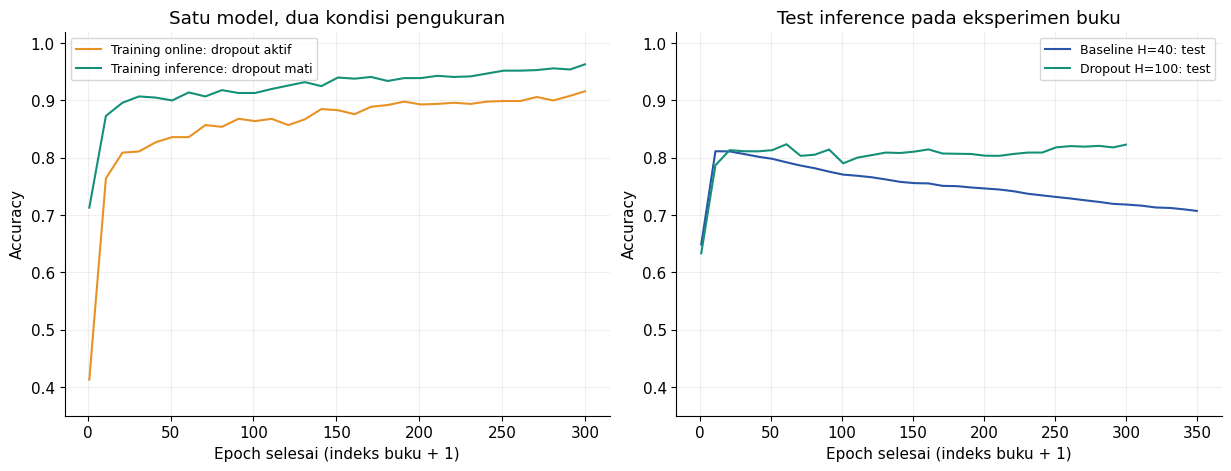

In [ ]:
# Visualisasi tambahan: kondisi inference dan training dropout dibedakan.
fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.6), layout='constrained')
drop_epochs = [row['epoch'] for row in dropout_history]
axes[0].plot(drop_epochs, [row['online_accuracy'] for row in dropout_history],
             color='#e89124', label='Training online: dropout aktif')
axes[0].plot(drop_epochs, [row['train']['accuracy'] for row in dropout_history],
             color='#159078', label='Training inference: dropout mati')
axes[0].set_title('Satu model, dua kondisi pengukuran')
axes[1].plot([row['epoch'] for row in baseline_history],
             [row['test']['accuracy'] for row in baseline_history],
             color='#2855a8', label='Baseline H=40: test')
axes[1].plot(drop_epochs, [row['test']['accuracy'] for row in dropout_history],
             color='#159078', label='Dropout H=100: test')
axes[1].set_title('Test inference pada eksperimen buku')
for ax in axes:
    ax.set_xlabel('Epoch selesai (indeks buku + 1)')
    ax.set_ylabel('Accuracy')
    ax.set_ylim(0.35, 1.02)
    ax.grid(alpha=0.2)
    ax.legend(fontsize=9)
plt.show()

## 16. Batch gradient descent: rata-rata kontribusi gradien

Mini-batch mengelompokkan $B$ sampel dan menghitung kontribusi gradien pada **bobot yang sama** sebelum satu update. Untuk loss rata-rata batch, gradiennya adalah rata-rata gradien per sampel:

$$
\nabla_W L_{\mathrm{batch}}=\frac1B\sum_{i=1}^B\nabla_W L_i.
$$

Jika kontribusi sampel memiliki variasi yang tidak sepenuhnya saling bergantung, averaging dapat mengurangi fluktuasi estimasi gradien. Keuntungan ini tidak menjamin loss selalu turun atau membenarkan learning rate sebesar apa pun. Batch size dan learning rate perlu dipertimbangkan bersama.

| Operasi | Shape saat B=100 dan hidden=100 |
| --- | --- |
| Input batch X | `(100, 784)` |
| W0 | `(784, 100)` |
| Preactivation, hidden, mask | `(100, 100)` |
| W1 | `(100, 10)` |
| Prediksi, target, delta output | `(100, 10)` |
| Delta hidden | `(100, 100)` |
| Gradien W0 = X.T @ delta hidden | `(784, 100)` |
| Gradien W1 = hidden.T @ delta output | `(100, 10)` |

Perkalian matriks memproses banyak weighted sum sekaligus dan dapat memakai operasi BLAS yang efisien. Kecepatan aktual tetap bergantung pada perangkat, ukuran matriks, jumlah thread, dan jumlah update yang benar-benar dilakukan.

**Rujukan:** Trask (2019), hlm. 158-160.

## 17. Reproduksi listing batch: memeriksa posisi update

Halaman 159 dan notebook pendamping penulis menempatkan perhitungan delta serta update di dalam `for k in range(batch_size)`, yang juga menghitung accuracy. Dengan batch size 100, setiap batch menghasilkan **100 update**, memakai activation dan prediksi yang sama selama loop tersebut. Perilaku ini telah diperiksa terhadap angka checkpoint awal pada halaman 158.

Karena terdapat 10 batch per epoch, jumlah update adalah 1.000 per epoch, atau **300.000** selama 300 epoch. Ini berbeda dari mini-batch dengan satu update per batch, yang menghasilkan 10 update per epoch. Delta hidden pada pengulangan berikutnya juga menggunakan W1 yang sudah berubah, meskipun prediksinya masih dari forward sebelumnya.

Alpha dicetak sebagai `0.001`, sedangkan narasi halaman 160 menyatakan 20 kali `0.005`. Secara numerik, `0.001` adalah 0,2 kali `0.005`, bukan 20 kali. Untuk W1, 100 pengulangan gradien yang tetap menghasilkan total perubahan setara faktor `100 × 0.001`; perubahan W0 tidak sesederhana itu karena delta hidden mengikuti W1 yang berubah.

Sel berikut mempertahankan alpha dan posisi loop sumber. Format indentasi dibuat menjadi Python yang valid sesuai notebook penulis. Bagian berikutnya menunjukkan implementasi satu update per batch dan aturan rantai yang konsisten sebagai pendalaman.

**Rujukan:** Trask (2019), hlm. 158-160; [notebook Chapter 8 penulis](https://github.com/iamtrask/Grokking-Deep-Learning/blob/master/Chapter8%20-%20Intro%20to%20Regularization%20-%20Learning%20Signal%20and%20Ignoring%20Noise.ipynb).

In [ ]:
# Reproduksi perilaku listing batch: update memang berada di loop k.
np.random.seed(1)
def relu(x):
    return (x >= 0) * x
def relu2deriv(output):
    return output >= 0

batch_size = 100
alpha, iterations = (0.001, 300)
pixels_per_image, num_labels, hidden_size = (784, 10, 100)
weights_0_1 = 0.2*np.random.random((pixels_per_image, hidden_size)) - 0.1
weights_1_2 = 0.2*np.random.random((hidden_size, num_labels)) - 0.1
batch_book_history = []
batch_book_updates = 0
batch_book_seconds = 0.0

for j in range(iterations):
    step_started = time.perf_counter()
    error, correct_cnt = (0.0, 0)
    for i in range(int(len(images) / batch_size)):
        batch_start, batch_end = (i*batch_size, (i+1)*batch_size)
        layer_0 = images[batch_start:batch_end]
        layer_1 = relu(np.dot(layer_0, weights_0_1))
        dropout_mask = np.random.randint(2, size=layer_1.shape)
        layer_1 *= dropout_mask * 2
        layer_2 = np.dot(layer_1, weights_1_2)
        error += np.sum((labels[batch_start:batch_end] - layer_2) ** 2)
        for k in range(batch_size):
            correct_cnt += int(np.argmax(layer_2[k:k+1]) ==
                               np.argmax(labels[batch_start+k:batch_start+k+1]))
            layer_2_delta = (labels[batch_start:batch_end] - layer_2) / batch_size
            layer_1_delta = layer_2_delta.dot(weights_1_2.T) * relu2deriv(layer_1)
            layer_1_delta *= dropout_mask
            weights_1_2 += alpha * layer_1.T.dot(layer_2_delta)
            weights_0_1 += alpha * layer_0.T.dot(layer_1_delta)
            batch_book_updates += 1
    batch_book_seconds += time.perf_counter() - step_started
    if j % 10 == 0 or j == iterations-1:
        train_fixed = evaluate_fixed(images, labels, weights_0_1, weights_1_2)
        validation_fixed = evaluate_fixed(validation_images, validation_labels, weights_0_1, weights_1_2)
        test_fixed = evaluate_fixed(test_images, test_labels, weights_0_1, weights_1_2)
        row = {'index': j, 'epoch': j+1, 'online_sse': float(error/len(images)),
               'online_accuracy': correct_cnt/len(images), 'train': train_fixed,
               'validation': validation_fixed, 'test': test_fixed}
        batch_book_history.append(row)
        print(f"I:{j} Test-Err:{test_fixed['mean_sse']:.6f} Test-Acc:{test_fixed['accuracy']:.4f} "
              f"Train-Err:{row['online_sse']:.6f} Train-Acc:{row['online_accuracy']:.4f}")

batch_book_weights = (weights_0_1.copy(), weights_1_2.copy())
print('Jumlah update listing batch:', batch_book_updates)

I:0 Test-Err:0.815007 Test-Acc:0.3832 Train-Err:1.284414 Train-Acc:0.1650
I:10 Test-Err:0.568571 Test-Acc:0.7173 Train-Err:0.591729 Train-Acc:0.6720
I:20 Test-Err:0.510345 Test-Acc:0.7571 Train-Err:0.532176 Train-Acc:0.7290
I:30 Test-Err:0.485419 Test-Acc:0.7793 Train-Err:0.498944 Train-Acc:0.7540
I:40 Test-Err:0.468131 Test-Acc:0.7877 Train-Err:0.489276 Train-Acc:0.7490
I:50 Test-Err:0.458592 Test-Acc:0.7930 Train-Err:0.468437 Train-Acc:0.7750
I:60 Test-Err:0.452813 Test-Acc:0.7995 Train-Err:0.452449 Train-Acc:0.7990
I:70 Test-Err:0.446270 Test-Acc:0.8030 Train-Err:0.453100 Train-Acc:0.7920
I:80 Test-Err:0.451386 Test-Acc:0.7968 Train-Err:0.457706 Train-Acc:0.7860
I:90 Test-Err:0.447816 Test-Acc:0.7950 Train-Err:0.454238 Train-Acc:0.7990
I:100 Test-Err:0.448632 Test-Acc:0.7930 Train-Err:0.447081 Train-Acc:0.7960
I:110 Test-Err:0.441301 Test-Acc:0.7943 Train-Err:0.426948 Train-Acc:0.8160
I:120 Test-Err:0.442375 Test-Acc:0.7966 Train-Err:0.431258 Train-Acc:0.8130
I:130 Test-Err:0.441313

In [ ]:
# Memeriksa angka tabel dan jumlah update dari struktur sumber.
batch_book_checkpoint_290 = next(row for row in batch_book_history if row['index'] == 290)
print('Indeks 0, SSE training online:', batch_book_history[0]['online_sse'])
print('Indeks 0, test accuracy:', batch_book_history[0]['test']['accuracy'])
print('Indeks 290, test accuracy:', batch_book_checkpoint_290['test']['accuracy'])
print('Indeks 299, test accuracy:', batch_book_history[-1]['test']['accuracy'])
print('Update tiap epoch sumber:', batch_book_updates // 300)
np.testing.assert_allclose(batch_book_history[0]['online_sse'], 1.284413870722451, rtol=1e-10)
assert batch_book_history[0]['test']['accuracy'] == 0.3832
assert batch_book_checkpoint_290['test']['accuracy'] == 0.7975
assert batch_book_updates == 300000

Indeks 0, SSE training online: 1.284413870722451
Indeks 0, test accuracy: 0.3832
Indeks 290, test accuracy: 0.7975
Indeks 299, test accuracy: 0.7992
Update tiap epoch sumber: 1000


## 18. Pendalaman: satu update per batch

Implementasi tambahan berikut mengikuti definisi mini-batch dan aturan rantai. Ada empat perbedaan yang disengaja dari listing sumber:

1. Satu update dilakukan setelah menghitung seluruh batch; penghitungan accuracy tidak membungkus update.
2. Mask turunan ReLU dihitung dari **preactivation > 0**.
3. Faktor inverted dropout `mask / keep_probability` digunakan pada forward maupun backward.
4. Kedua gradien dihitung sebelum ada bobot yang diperbarui.

Alpha tambahan ditetapkan **0.1**, yaitu 20 × 0.005, sebagai ilustrasi yang mengikuti angka pada narasi. Parameter ini ditetapkan untuk eksperimen tambahan, bukan dioptimalkan dari test accuracy. Hidden width 100, batch size 100, keep probability 0.5, seed 1, dan 300 epoch tetap digunakan.

Perbedaan alpha, mask, serta struktur update membuat eksperimen ini berbeda dari reproduksi sumber. Hasilnya tidak digunakan untuk mengklaim bahwa memindahkan satu indentasi saja menyebabkan suatu peningkatan tertentu.

In [ ]:
# Tambahan: mini-batch dengan gradien yang konsisten dan satu update per batch.
corrected_rng = np.random.RandomState(1)
corrected_w0 = 0.2*corrected_rng.random_sample((784, 100)) - 0.1
corrected_w1 = 0.2*corrected_rng.random_sample((100, 10)) - 0.1
corrected_alpha = 0.1
corrected_batch_size = 100
corrected_keep = 0.5
corrected_iterations = 300
corrected_history = []
corrected_updates = 0
corrected_seconds = 0.0

for j in range(corrected_iterations):
    step_started = time.perf_counter()
    online_sse, online_correct = 0.0, 0
    for start in range(0, len(images), corrected_batch_size):
        x_batch = images[start:start+corrected_batch_size]
        y_batch = labels[start:start+corrected_batch_size]
        actual_batch_size = len(x_batch)
        z_hidden = x_batch @ corrected_w0
        hidden_before_dropout = relu(z_hidden)
        mask = corrected_rng.randint(2, size=hidden_before_dropout.shape)
        hidden_training = hidden_before_dropout * mask / corrected_keep
        predictions = hidden_training @ corrected_w1
        online_sse += np.sum((predictions - y_batch) ** 2)
        online_correct += int(np.sum(np.argmax(predictions, axis=1) ==
                                     np.argmax(y_batch, axis=1)))

        # Loss = SSE / (2 * actual_batch_size), konvensi gradien dan update minus.
        delta_output = (predictions - y_batch) / actual_batch_size
        delta_hidden = (delta_output @ corrected_w1.T) * (z_hidden > 0)
        delta_hidden *= mask / corrected_keep
        grad_w1 = hidden_training.T @ delta_output
        grad_w0 = x_batch.T @ delta_hidden
        corrected_w1 -= corrected_alpha * grad_w1
        corrected_w0 -= corrected_alpha * grad_w0
        corrected_updates += 1
    corrected_seconds += time.perf_counter() - step_started
    if j % 10 == 0 or j == corrected_iterations-1:
        train_fixed = evaluate_fixed(images, labels, corrected_w0, corrected_w1)
        validation_fixed = evaluate_fixed(validation_images, validation_labels, corrected_w0, corrected_w1)
        test_fixed = evaluate_fixed(test_images, test_labels, corrected_w0, corrected_w1)
        row = {'index': j, 'epoch': j+1, 'online_sse': float(online_sse/len(images)),
               'online_accuracy': online_correct/len(images), 'train': train_fixed,
               'validation': validation_fixed, 'test': test_fixed}
        corrected_history.append(row)
        print(f"I:{j} Test-Err:{test_fixed['mean_sse']:.6f} Test-Acc:{test_fixed['accuracy']:.4f} "
              f"Train-Err:{row['online_sse']:.6f} Train-Acc:{row['online_accuracy']:.4f}")

corrected_weights = (corrected_w0.copy(), corrected_w1.copy())
print('Jumlah update mini-batch konsisten:', corrected_updates)
assert corrected_updates == 3000

I:0 Test-Err:0.797128 Test-Acc:0.4225 Train-Err:1.202922 Train-Acc:0.1900
I:10 Test-Err:0.496590 Test-Acc:0.7571 Train-Err:0.527600 Train-Acc:0.7230
I:20 Test-Err:0.411500 Test-Acc:0.8058 Train-Err:0.434322 Train-Acc:0.8180
I:30 Test-Err:0.369016 Test-Acc:0.8298 Train-Err:0.379633 Train-Acc:0.8430
I:40 Test-Err:0.345137 Test-Acc:0.8452 Train-Err:0.354185 Train-Acc:0.8600
I:50 Test-Err:0.323061 Test-Acc:0.8571 Train-Err:0.323925 Train-Acc:0.8960
I:60 Test-Err:0.313736 Test-Acc:0.8648 Train-Err:0.311461 Train-Acc:0.9000
I:70 Test-Err:0.306219 Test-Acc:0.8662 Train-Err:0.295579 Train-Acc:0.9060
I:80 Test-Err:0.299527 Test-Acc:0.8696 Train-Err:0.279971 Train-Acc:0.9020
I:90 Test-Err:0.293951 Test-Acc:0.8746 Train-Err:0.273122 Train-Acc:0.9180
I:100 Test-Err:0.287313 Test-Acc:0.8765 Train-Err:0.259557 Train-Acc:0.9220
I:110 Test-Err:0.289365 Test-Acc:0.8774 Train-Err:0.250332 Train-Acc:0.9340
I:120 Test-Err:0.281819 Test-Acc:0.8764 Train-Err:0.244869 Train-Acc:0.9340
I:130 Test-Err:0.282903

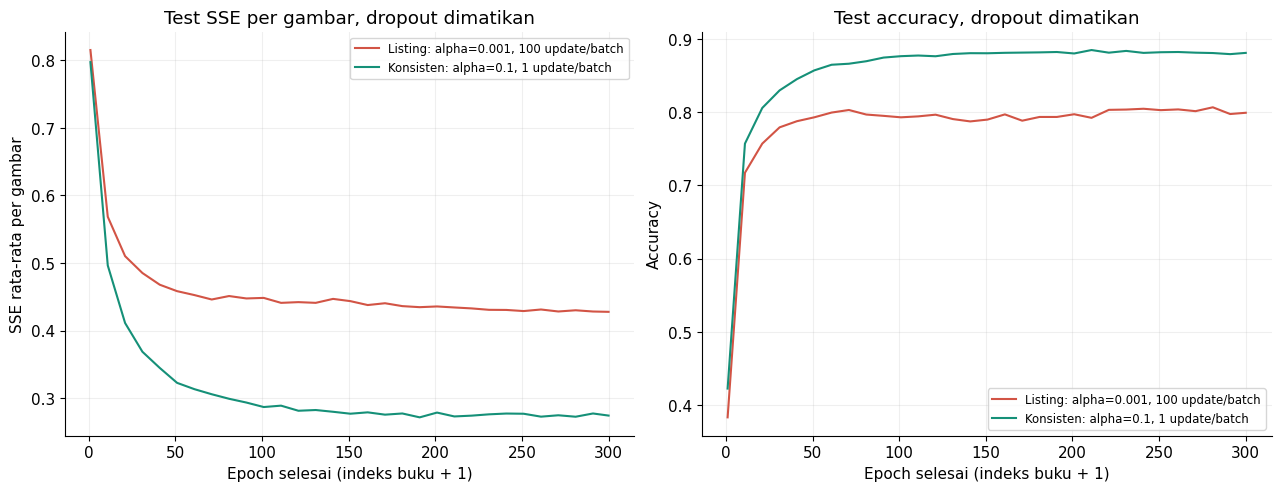

In [ ]:
# Visualisasi tambahan: dua implementasi beserta konfigurasi masing-masing.
fig, axes = plt.subplots(1, 2, figsize=(12.7, 4.8), layout='constrained')
for history, label, color in [
    (batch_book_history, 'Listing: alpha=0.001, 100 update/batch', '#d25445'),
    (corrected_history, 'Konsisten: alpha=0.1, 1 update/batch', '#159078'),
]:
    epochs = [row['epoch'] for row in history]
    axes[0].plot(epochs, [row['test']['mean_sse'] for row in history],
                 label=label, color=color)
    axes[1].plot(epochs, [row['test']['accuracy'] for row in history],
                 label=label, color=color)
axes[0].set_title('Test SSE per gambar, dropout dimatikan')
axes[0].set_ylabel('SSE rata-rata per gambar')
axes[1].set_title('Test accuracy, dropout dimatikan')
axes[1].set_ylabel('Accuracy')
for ax in axes:
    ax.set_xlabel('Epoch selesai (indeks buku + 1)')
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8.5)
plt.show()

## 19. Membaca perbandingan batch dan waktu komputasi

Mini-batch konsisten menghasilkan 10 update per epoch pada 1.000 sampel, sedangkan listing menghasilkan 1.000 update per epoch. Perbedaan jumlah operasi ini perlu diketahui sebelum membandingkan waktu training. Timer notebook hanya mencatat loop training, tidak memasukkan waktu unduhan, evaluasi, pembuatan grafik, atau pembacaan checkpoint.

Source memakai `int(len(images) / batch_size)`, yang akan mengabaikan sisa jika jumlah gambar tidak habis dibagi batch size. Pada contoh sumber, 1.000 habis dibagi 100, sehingga tidak ada sampel terbuang. Pendalaman memakai slice sampai akhir serta membagi delta dengan ukuran batch yang benar-benar diproses.

Rata-rata gradien batch tidak sama dengan menjalankan SGD berurutan pada seluruh anggota batch: pada SGD, bobot berubah setelah tiap sampel. Kesetaraan rata-rata hanya berlaku ketika seluruh gradien per sampel dievaluasi pada bobot dan mask yang sama dengan perhitungan batch.

Grafik membandingkan konfigurasi yang berbeda secara deskriptif. Accuracy, loss, serta waktu perlu dibaca bersama ukuran model, learning rate, jumlah epoch, mode dropout, dan jumlah update. Waktu yang diperoleh pada CPU ini tidak menjadi jaminan waktu yang sama di Colab.

**Rujukan:** Trask (2019), hlm. 158-160; pemeriksaan struktur dan pengukuran adalah tambahan notebook.

## 20. Pendalaman rumus: gradien ReLU dengan inverted dropout

Untuk satu batch, misalkan $Z=XW_0$, $H=\operatorname{ReLU}(Z)$, $\tilde H=H\odot M/q$, dan $P=\tilde HW_1$. Gunakan loss:

$$
L=\frac{1}{2B}\sum_{i=1}^B\sum_{c=1}^{10}(P_{ic}-Y_{ic})^2.
$$

Aturan rantai memberikan:

$$
D_2=\frac{P-Y}{B},\qquad
D_1=(D_2W_1^T)\odot\mathbf1_{Z>0}\odot\frac{M}{q},
$$

$$
G_1=\tilde H^TD_2,\qquad G_0=X^TD_1,\qquad
W_k\leftarrow W_k-\alpha G_k.
$$

Mask ReLU memakai $Z$ sebelum activation. Faktor $M/q$ berasal dari turunan scaling dropout, bukan sekadar pilihan logging. Gradien W1 sudah mencakup scaling karena memakai $\tilde H$; gradien W0 juga perlu melewati faktor tersebut saat backward.

Pemeriksaan berikut memakai jaringan toy 3-4-2, dua sampel, serta **mask tetap**. Mask harus sama pada evaluasi loss plus dan minus agar finite difference mengukur fungsi yang sama. Seluruh preactivation jauh dari nol untuk menghindari titik nondifferentiable ReLU.

Rumus ini memeriksa konsistensi matematis implementasi tambahan. Reproduksi sumber tetap menggunakan mask serta update sumber yang telah dijelaskan.

In [ ]:
# Tambahan: pemeriksaan gradien numerik pada ReLU + inverted dropout.
def consistent_loss_and_gradients(x, y, w0, w1, mask, keep):
    z = x @ w0
    h = relu(z) * mask / keep
    predictions = h @ w1
    loss = float(0.5 * np.sum((predictions - y) ** 2) / len(x))
    d2 = (predictions - y) / len(x)
    d1 = (d2 @ w1.T) * (z > 0) * mask / keep
    return loss, x.T @ d1, h.T @ d2

toy_x = np.array([[0.4, -0.2, 0.7], [0.3, 0.8, -0.1]])
toy_y = np.array([[1.0, 0.0], [0.0, 1.0]])
toy_w0 = np.array([[0.5, -0.4, 0.2, 0.7],
                   [-0.3, 0.6, -0.5, 0.1],
                   [0.2, 0.3, -0.6, 0.4]])
toy_w1 = np.array([[0.3, -0.2], [-0.4, 0.5], [0.6, 0.2], [0.1, -0.3]])
toy_mask = np.array([[1, 1, 0, 1], [1, 1, 1, 0]])
toy_keep = 0.5
toy_loss, analytical_w0, analytical_w1 = consistent_loss_and_gradients(
    toy_x, toy_y, toy_w0, toy_w1, toy_mask, toy_keep)
epsilon = 1e-6
assert np.min(np.abs(toy_x @ toy_w0)) > 100*epsilon
numerical_gradients = []
for parameter in [toy_w0, toy_w1]:
    numerical = np.zeros_like(parameter)
    for index in np.ndindex(parameter.shape):
        original_value = parameter[index]
        parameter[index] = original_value + epsilon
        plus = consistent_loss_and_gradients(toy_x, toy_y, toy_w0, toy_w1, toy_mask, toy_keep)[0]
        parameter[index] = original_value - epsilon
        minus = consistent_loss_and_gradients(toy_x, toy_y, toy_w0, toy_w1, toy_mask, toy_keep)[0]
        parameter[index] = original_value
        numerical[index] = (plus - minus) / (2*epsilon)
    numerical_gradients.append(numerical)
np.testing.assert_allclose(analytical_w0, numerical_gradients[0], rtol=1e-5, atol=1e-7)
np.testing.assert_allclose(analytical_w1, numerical_gradients[1], rtol=1e-5, atol=1e-7)
gradient_max_error = max(float(np.max(np.abs(analytical_w0 - numerical_gradients[0]))),
                         float(np.max(np.abs(analytical_w1 - numerical_gradients[1]))))

# Membandingkan ekspresi mask listing dengan turunan loss yang sama.
toy_hidden = relu(toy_x @ toy_w0) * toy_mask / toy_keep
toy_delta = (toy_hidden @ toy_w1 - toy_y) / len(toy_x)
listing_hidden_delta = (toy_delta @ toy_w1.T) * (toy_hidden >= 0) * toy_mask
listing_w0_gradient = toy_x.T @ listing_hidden_delta
listing_gradient_gap = float(np.max(np.abs(listing_w0_gradient - analytical_w0)))
print('Jumlah parameter yang diperiksa:', toy_w0.size + toy_w1.size)
print('Selisih maksimum gradien konsisten vs finite difference:', gradient_max_error)
print('Selisih ekspresi mask listing vs gradien konsisten W0:', listing_gradient_gap)
assert listing_gradient_gap > 1e-4
print('Gradien konsisten lulus; ekspresi mask listing berbeda dari turunan loss ini.')

Jumlah parameter yang diperiksa: 20
Selisih maksimum gradien konsisten vs finite difference: 2.6035236466714906e-11
Selisih ekspresi mask listing vs gradien konsisten W0: 0.11696000000000001
Gradien konsisten lulus; ekspresi mask listing berbeda dari turunan loss ini.


## 21. Memeriksa rata-rata gradien batch

Pada bobot yang sama dan mask yang ditetapkan untuk setiap sampel, gradien batch rata-rata sama dengan rata-rata gradien tiap sampel. Pemeriksaan ini menggunakan fungsi gradien konsisten yang baru saja diuji secara numerik.

Membagi delta output dengan $B$ sudah membagi kedua gradien melalui aturan rantai. Membagi gradien lagi dengan $B$ akan memberikan normalisasi ganda. Sebaliknya, tanpa pembagian tersebut, besar update bergantung pada jumlah sampel yang dijumlahkan.

In [ ]:
# Tambahan: batch gradient sama dengan mean gradient per sampel pada state tetap.
sample_w0_gradients, sample_w1_gradients = [], []
for i in range(len(toy_x)):
    _, g0, g1 = consistent_loss_and_gradients(
        toy_x[i:i+1], toy_y[i:i+1], toy_w0, toy_w1,
        toy_mask[i:i+1], toy_keep)
    sample_w0_gradients.append(g0)
    sample_w1_gradients.append(g1)
np.testing.assert_allclose(np.mean(sample_w0_gradients, axis=0), analytical_w0)
np.testing.assert_allclose(np.mean(sample_w1_gradients, axis=0), analytical_w1)
print('Rata-rata gradien per sampel sama dengan gradien batch pada bobot dan mask tetap.')

Rata-rata gradien per sampel sama dengan gradien batch pada bobot dan mask tetap.


## 22. Perbandingan hasil eksekusi

Semua metrik pada tabel berikut dihitung dalam mode **inference**, tanpa dropout dan tanpa update. Baris checkpoint validation berasal dari bobot yang dipilih monitor baseline, bukan dari training terpisah. Baris baseline memakai 350 epoch; dropout dan kedua versi batch memakai 300 epoch.

Angka tabel merupakan snapshot eksekusi saat penyusunan. Jika mengubah parameter lalu menjalankan ulang, gunakan output terbaru pada sel kode serta grafik yang diperbarui.

In [ ]:
# Tambahan: mengumpulkan hasil nyata setiap eksperimen.
comparison_rows = [
    {'model': 'Baseline H=40, 350 epoch', **{key: baseline_history[-1][key]
                                         for key in ['train', 'validation', 'test']}},
    {'model': f"Checkpoint validation H=40, epoch {early_state['best_index']+1}",
     'train': early_train, 'validation': early_validation, 'test': early_test},
    {'model': 'Dropout buku H=100, 300 epoch', **{key: dropout_history[-1][key]
                                               for key in ['train', 'validation', 'test']}},
    {'model': 'Batch buku, alpha=0.001', **{key: batch_book_history[-1][key]
                                         for key in ['train', 'validation', 'test']}},
    {'model': 'Mini-batch konsisten, alpha=0.1', **{key: corrected_history[-1][key]
                                                 for key in ['train', 'validation', 'test']}},
]
table_lines = ['| Model / checkpoint | Train accuracy | Validation accuracy | Test accuracy | Test SSE/gambar |',
               '| --- | --- | --- | --- | --- |']
for row in comparison_rows:
    table_lines.append(f"| {row['model']} | {row['train']['accuracy']*100:.2f}% | "
                       f"{row['validation']['accuracy']*100:.2f}% | {row['test']['accuracy']*100:.2f}% | "
                       f"{row['test']['mean_sse']:.6f} |")
    print(f"{row['model']}: Train-Acc={row['train']['accuracy']:.4f}, "
          f"Validation-Acc={row['validation']['accuracy']:.4f}, "
          f"Test-Acc={row['test']['accuracy']:.4f}, Test-SSE/N={row['test']['mean_sse']:.6f}")
comparison_table = '\n'.join(table_lines)
print()
print('Waktu loop training pada lingkungan eksekusi ini, tanpa waktu evaluasi:')
for name, seconds, updates in [
    ('Baseline', baseline_seconds, baseline_updates),
    ('Dropout sumber', dropout_seconds, dropout_updates),
    ('Batch sumber', batch_book_seconds, batch_book_updates),
    ('Mini-batch konsisten', corrected_seconds, corrected_updates),
]:
    print(f'{name}: {seconds:.2f} detik; {updates:,} update')

Baseline H=40, 350 epoch: Train-Acc=0.9990, Validation-Acc=0.7090, Test-Acc=0.7073, Test-SSE/N=0.653406
Checkpoint validation H=40, epoch 14: Train-Acc=0.9220, Validation-Acc=0.8120, Test-Acc=0.8121, Test-SSE/N=0.416253
Dropout buku H=100, 300 epoch: Train-Acc=0.9630, Validation-Acc=0.8180, Test-Acc=0.8229, Test-SSE/N=0.393144
Batch buku, alpha=0.001: Train-Acc=0.9050, Validation-Acc=0.7880, Test-Acc=0.7992, Test-SSE/N=0.428027
Mini-batch konsisten, alpha=0.1: Train-Acc=0.9980, Validation-Acc=0.8840, Test-Acc=0.8810, Test-SSE/N=0.274691

Waktu loop training pada lingkungan eksekusi ini, tanpa waktu evaluasi:
Baseline: 51.47 detik; 350,000 update
Dropout sumber: 106.67 detik; 300,000 update
Batch sumber: 309.07 detik; 300,000 update
Mini-batch konsisten: 6.46 detik; 3,000 update


| Model / checkpoint | Train accuracy | Validation accuracy | Test accuracy | Test SSE/gambar |
| --- | --- | --- | --- | --- |
| Baseline H=40, 350 epoch | 99.90% | 70.90% | 70.73% | 0.653406 |
| Checkpoint validation H=40, epoch 14 | 92.20% | 81.20% | 81.21% | 0.416253 |
| Dropout buku H=100, 300 epoch | 96.30% | 81.80% | 82.29% | 0.393144 |
| Batch buku, alpha=0.001 | 90.50% | 78.80% | 79.92% | 0.428027 |
| Mini-batch konsisten, alpha=0.1 | 99.80% | 88.40% | 88.10% | 0.274691 |

Pada eksekusi ini, accuracy training online baseline mencapai **100%**, sedangkan accuracy inference pada bobot akhir adalah **99,90%**. Keduanya memakai waktu pengukuran berbeda: log menghitung setiap sampel sebelum update pada state bobot yang terus berubah, sementara tabel mengevaluasi seluruh sampel dengan satu state bobot akhir. Pembaruan setelah suatu sampel diproses dapat mengubah prediksi untuk sampel tersebut.

Perbandingan ini bersifat deskriptif. Baseline dan dropout berbeda ukuran model serta jumlah epoch. Dua versi batch berbeda alpha, mask turunan, scaling backward, dan frekuensi update. Angka dari satu seed serta 1.000 gambar training belum cukup untuk menyimpulkan metode terbaik secara umum.

In [ ]:
# Tambahan: kelas yang benar tidak menuntut skor sama dengan one-hot target.
baseline_scores = relu(images @ baseline_weights[0]) @ baseline_weights[1]
per_image_sse = np.sum((baseline_scores - labels) ** 2, axis=1)
correct_classes = np.argmax(baseline_scores, axis=1) == np.argmax(labels, axis=1)
example_index = int(np.flatnonzero(correct_classes & (per_image_sse > 1e-8))[0])
print('Indeks contoh training:', example_index)
print('Target one-hot:', labels[example_index])
print('Skor model:', baseline_scores[example_index])
print('Kelas prediksi / target:', int(np.argmax(baseline_scores[example_index])),
      int(np.argmax(labels[example_index])))
print('SSE contoh yang terklasifikasi benar:', per_image_sse[example_index])
assert per_image_sse[example_index] > 0

Indeks contoh training: 0
Target one-hot: [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]
Skor model: [-0.024275 -0.067875  0.135879  0.211148 -0.054977  0.669828 -0.001271
 -0.015702 -0.055833 -0.010673]
Kelas prediksi / target: 5 5
SSE contoh yang terklasifikasi benar: 0.18375802175869835


## 23. Ringkasan konsep penting

| Konsep | Hal yang perlu diingat |
| --- | --- |
| Training accuracy | Mengukur kecocokan label; perlu dibaca bersama loss dan mode pengukuran |
| Generalisasi | Performa pada data yang tidak digunakan untuk update |
| Overfitting | Model cocok dengan pola training yang kurang berguna pada data lain |
| Signal dan noise | Relevansi informasi bergantung pada tugas dan distribusi data |
| Early stopping | Gunakan validation untuk memilih checkpoint, lalu pulihkan bobot tersimpan |
| Patience | Toleransi terhadap epoch tanpa perbaikan yang cukup |
| Dropout | Mask acak mematikan unit selama training |
| Inverted dropout | Forward dan backward melewati faktor mask / keep probability |
| Inference | Dropout dimatikan; output tetap berupa skor linear pada bab ini |
| Ensemble | Intuisi berbagi banyak subnetwork, bukan model independen dengan bobot terpisah |
| Mini-batch | Rata-rata kontribusi gradien pada state bobot yang sama, satu update per batch |
| Shape gradien | Selalu sama dengan matriks parameter yang diperbarui |
| Reproduksi dan teori | Hasil sumber dapat direproduksi meskipun implementasinya perlu dikritisi |
| Error log | SSE/N adalah rata-rata SSE per gambar; bukan MSE per elemen output |

Regularisasi dan batching menangani aspek berbeda: regularisasi berusaha mendorong generalisasi, sedangkan batching mengatur cara menghitung serta menerapkan update. Keduanya dapat digunakan bersama, seperti dropout pada hidden layer dan optimisasi mini-batch.

## 24. Verifikasi akhir

Pemeriksaan berikut memastikan semua epoch sumber selesai, checkpoint penting sesuai angka buku, seluruh bobot finite, jumlah update mengikuti kode, serta rumus tambahan lulus finite difference. Pemeriksaan gradien berlaku untuk implementasi tambahan yang konsisten, bukan klaim bahwa backward listing sumber memenuhi rumus tersebut.

In [ ]:
# Verifikasi reproduksi serta pendalaman.
assert baseline_history[-1]['index'] == 349
assert dropout_history[-1]['index'] == 299
assert batch_book_history[-1]['index'] == 299
assert corrected_history[-1]['index'] == 299
assert len(baseline_validation_history) == 350
assert baseline_updates == 350000
assert dropout_updates == 300000
assert batch_book_updates == 300000
assert corrected_updates == 3000
assert baseline_history[-1]['test']['accuracy'] == 0.7073
assert dropout_checkpoint_290['test']['accuracy'] == 0.8181
assert batch_book_checkpoint_290['test']['accuracy'] == 0.7975
assert early_state['weights'] is not None
assert early_state['stop_index'] is not None
assert gradient_max_error < 1e-7
for w0, w1 in [baseline_weights, dropout_weights, batch_book_weights, corrected_weights, early_weights]:
    assert w0.shape[0] == 784 and w1.shape[1] == 10
    assert w0.shape[1] == w1.shape[0]
    assert np.isfinite(w0).all() and np.isfinite(w1).all()
for row in comparison_rows:
    for split in ['train', 'validation', 'test']:
        assert 0 <= row[split]['accuracy'] <= 1
        assert np.isfinite(row[split]['mean_sse']) and row[split]['mean_sse'] >= 0
print('Seluruh verifikasi lulus.')
print('Tiga program sumber dan implementasi tambahan menyelesaikan semua epoch.')
print('Angka checkpoint sumber sesuai; gradien tambahan lulus finite difference.')
print('Total update empat program:', baseline_updates + dropout_updates +
      batch_book_updates + corrected_updates)

Seluruh verifikasi lulus.
Tiga program sumber dan implementasi tambahan menyelesaikan semua epoch.
Angka checkpoint sumber sesuai; gradien tambahan lulus finite difference.
Total update empat program: 953000
